# Step 6 – Federated Clients
**Project:** Paper Leak Sentiment Analysis Using Federated Learning

In federated learning, data is **not** pooled. Each data owner (a **client**) keeps its own comments, and only model updates travel to the server.
In our simulation, each **platform is one client**:

| Client | Holds |
|---|---|
| YouTube | only YouTube comments |
| X | only X (Twitter) comments |
| Instagram | only Instagram comments |
| Reddit | only Reddit comments |
| NewsPortal | only news-site comments |

We also build an **IID comparison**: the same data shuffled into 5 equal random clients. Step 8 uses it to show how much harder the realistic split is.

The **test set is never split**. It stays with the evaluator and is used only to score the final models.

In [1]:
import sys, json
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import split_clients
split_clients.main()          # writes data/clients/*.csv and data/clients_iid/*.csv

      client  train_rows  val_rows  share_of_data  pct_negative  pct_neutral  pct_positive  pct_hinglish_or_hindi  js_divergence_from_global
     YouTube       17652      2231          0.221         0.414        0.240         0.346                  0.550                      0.009
           X       20846      2530          0.261         0.369        0.318         0.313                  0.286                      0.001
   Instagram       15465      1943          0.193         0.352        0.208         0.441                  0.415                      0.016
      Reddit       13347      1670          0.167         0.277        0.449         0.274                  0.058                      0.010
  NewsPortal       12692      1626          0.159         0.200        0.520         0.280                  0.054                      0.029
IID client 1       16001      2000          0.200         0.333        0.334         0.333                  0.298                      0.000
IID client 2 

In [2]:
from matplotlib import font_manager
FONT = "Segoe UI" if any(f.name == "Segoe UI" for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SENT = {"negative": "#e34948", "neutral": "#898781", "positive": "#2a78d6"}; ORDER = list(SENT)
PLATFORMS = ["YouTube", "X", "Instagram", "Reddit", "NewsPortal"]
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]; PCOL = dict(zip(PLATFORMS, CAT))
plt.rcParams.update({"font.family": FONT, "font.size": 10, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
    "savefig.dpi": 200, "savefig.bbox": "tight"})
FIG = ROOT / "results/figures"
def title(ax, main, sub=None):
    ax.set_title(main, loc="left", fontsize=13, fontweight="bold", color=INK, pad=24 if sub else 10)
    if sub: ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom")
clients = {p: pd.read_csv(ROOT / f"data/clients/{p.lower()}_train.csv") for p in PLATFORMS}
iid = {f"IID {k}": pd.read_csv(ROOT / f"data/clients_iid/client{k}_train.csv") for k in range(1, 6)}
stats = pd.read_csv(ROOT / "results/tables/client_statistics.csv")

## 1. How the clients differ (three kinds of non-IID data)
Real federated data is **non-IID**: clients do not look like each other or like the whole dataset. Our clients differ in three ways:
1. **Quantity skew**: some clients have more data than others.
2. **Label skew**: the share of negative, neutral and positive comments differs.
3. **Feature (language) skew**: some clients write mostly Hinglish, others almost only English.

In [3]:
show = stats.head(5)[["client", "train_rows", "val_rows", "share_of_data", "pct_negative", "pct_neutral", "pct_positive", "pct_hinglish_or_hindi"]].copy()
show.columns = ["Client", "Train comments", "Val comments", "Share of data", "Negative", "Neutral", "Positive", "Hinglish/Hindi"]
show.style.format({c: "{:.0%}" for c in ["Share of data", "Negative", "Neutral", "Positive", "Hinglish/Hindi"]} | {"Train comments": "{:,}", "Val comments": "{:,}"}).hide(axis="index")

Client,Train comments,Val comments,Share of data,Negative,Neutral,Positive,Hinglish/Hindi
YouTube,"17,652","2,231",22%,41%,24%,35%,55%
X,"20,846","2,530",26%,37%,32%,31%,29%
Instagram,"15,465","1,943",19%,35%,21%,44%,41%
Reddit,"13,347","1,670",17%,28%,45%,27%,6%
NewsPortal,"12,692","1,626",16%,20%,52%,28%,5%


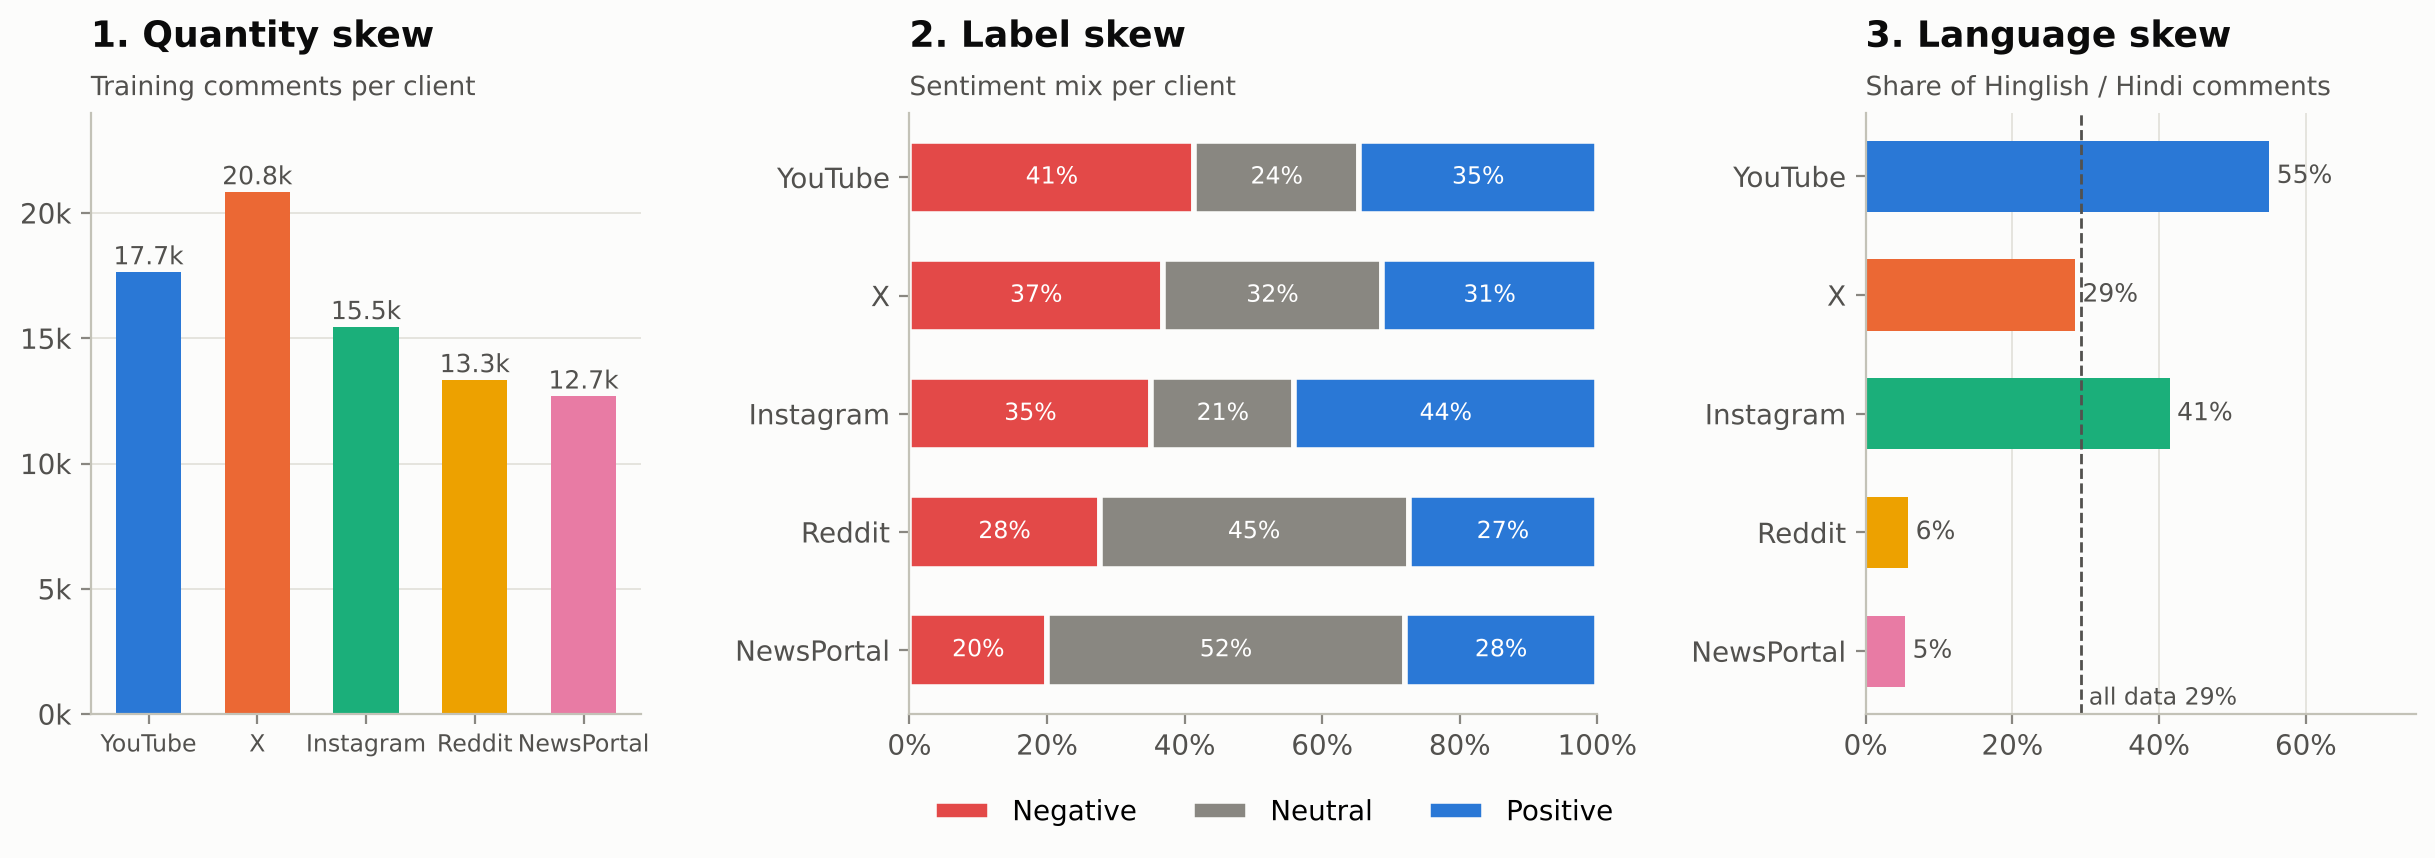

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1, 1.25, 1], "wspace": 0.45})
# (a) quantity
sizes = [len(clients[p]) for p in PLATFORMS]
axes[0].bar(PLATFORMS, sizes, color=[PCOL[p] for p in PLATFORMS], width=0.6)
for i, v in enumerate(sizes):
    axes[0].text(i, v + 300, f"{v/1000:.1f}k", ha="center", fontsize=9, color=INK2)
axes[0].grid(axis="x", visible=False); axes[0].set_ylim(0, max(sizes) * 1.15)
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x/1000:g}k"); axes[0].tick_params(axis="x", labelsize=8.5)
title(axes[0], "1. Quantity skew", "Training comments per client")
# (b) labels
mix = pd.DataFrame({p: clients[p].label.value_counts(normalize=True) for p in PLATFORMS}).T[ORDER]
left = np.zeros(5)
for c in ORDER:
    axes[1].barh(PLATFORMS, mix[c], left=left, color=SENT[c], edgecolor=SURFACE, linewidth=2, height=0.62, label=c.capitalize())
    for i, (l, v) in enumerate(zip(left, mix[c])):
        axes[1].text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=8.5, color="#ffffff")
    left += mix[c].values
axes[1].invert_yaxis(); axes[1].set_xlim(0, 1); axes[1].grid(False)
axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[1].legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.1))
title(axes[1], "2. Label skew", "Sentiment mix per client")
# (c) language
lang = [clients[p].language.isin(["hinglish", "hi"]).mean() for p in PLATFORMS]
axes[2].barh(PLATFORMS, lang, color=[PCOL[p] for p in PLATFORMS], height=0.6)
avg = pd.concat(clients.values()).language.isin(["hinglish", "hi"]).mean()
axes[2].axvline(avg, color=INK2, lw=1, ls="--"); axes[2].text(avg + 0.01, 4.45, f"all data {avg:.0%}", fontsize=8.5, color=INK2)
for i, v in enumerate(lang):
    axes[2].text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9, color=INK2)
axes[2].invert_yaxis(); axes[2].set_xlim(0, 0.75); axes[2].grid(axis="y", visible=False)
axes[2].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
title(axes[2], "3. Language skew", "Share of Hinglish / Hindi comments")
fig.savefig(FIG / "E1_client_differences.png"); plt.show()

- **YouTube** is the most negative and more than half Hinglish.
- **NewsPortal** is the most neutral, smallest and almost entirely English.
- A model trained only on NewsPortal would therefore see very little Hinglish and would probably struggle on YouTube-style comments. **This is exactly the gap federated learning should close.**

## 2. Vocabulary overlap between clients
How many of the words a client uses also appear on another client? Low overlap means a model trained on one client has never seen many of the words on another.

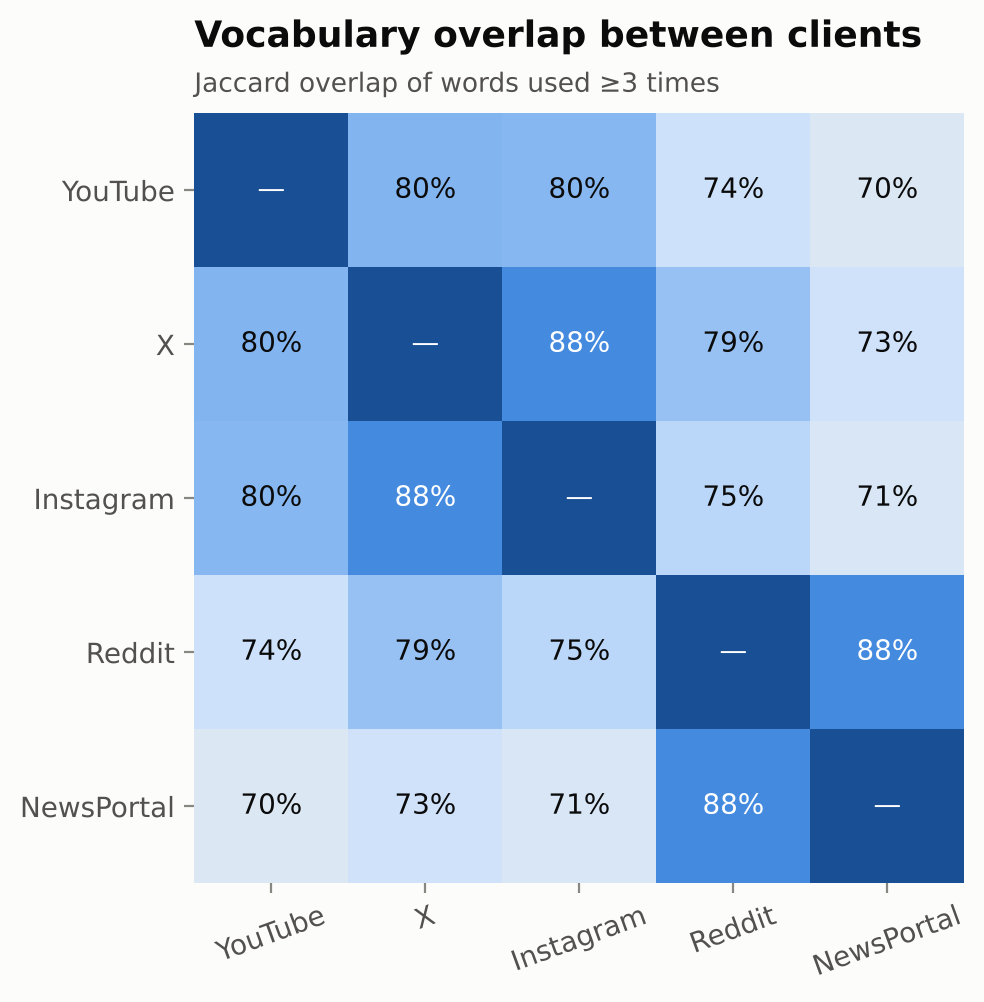

{'YouTube': '2,009 words', 'X': '2,009 words', 'Instagram': '1,960 words', 'Reddit': '1,624 words', 'NewsPortal': '1,554 words'}


In [5]:
def vocab(df, min_count=3):
    c = Counter(w for t in df.clean_text for w in str(t).split())
    return {w for w, n in c.items() if n >= min_count}
V = {p: vocab(clients[p]) for p in PLATFORMS}
J = pd.DataFrame([[len(V[a] & V[b]) / len(V[a] | V[b]) for b in PLATFORMS] for a in PLATFORMS], index=PLATFORMS, columns=PLATFORMS)
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("b", ["#f0efec", "#cde2fb", "#6da7ec", "#2a78d6", "#184f95"])
fig, ax = plt.subplots(figsize=(6.4, 5))
off = J.values[~np.eye(5, dtype=bool)]
vmin = off.min() - 0.05
ax.imshow(J.values, cmap=blues, vmin=vmin, vmax=1)
for i in range(5):
    for j in range(5):
        v = J.values[i, j]
        ax.text(j, i, "—" if i == j else f"{v:.0%}", ha="center", va="center", fontsize=10,
                color="#ffffff" if (i == j or (v - vmin) / (1 - vmin) > 0.55) else INK)
ax.set_xticks(range(5), PLATFORMS, rotation=20); ax.set_yticks(range(5), PLATFORMS); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
title(ax, "Vocabulary overlap between clients", "Jaccard overlap of words used ≥3 times")
fig.savefig(FIG / "E2_vocabulary_overlap.png"); plt.show()
print({p: f"{len(V[p]):,} words" for p in PLATFORMS})

English-heavy clients (Reddit, NewsPortal) share most of their vocabulary with each other. Hinglish-heavy clients (YouTube, Instagram) overlap less with them.

## 3. Non-IID vs IID clients
**Jensen–Shannon divergence** measures how far a client's sentiment mix is from the whole dataset (0 = identical).

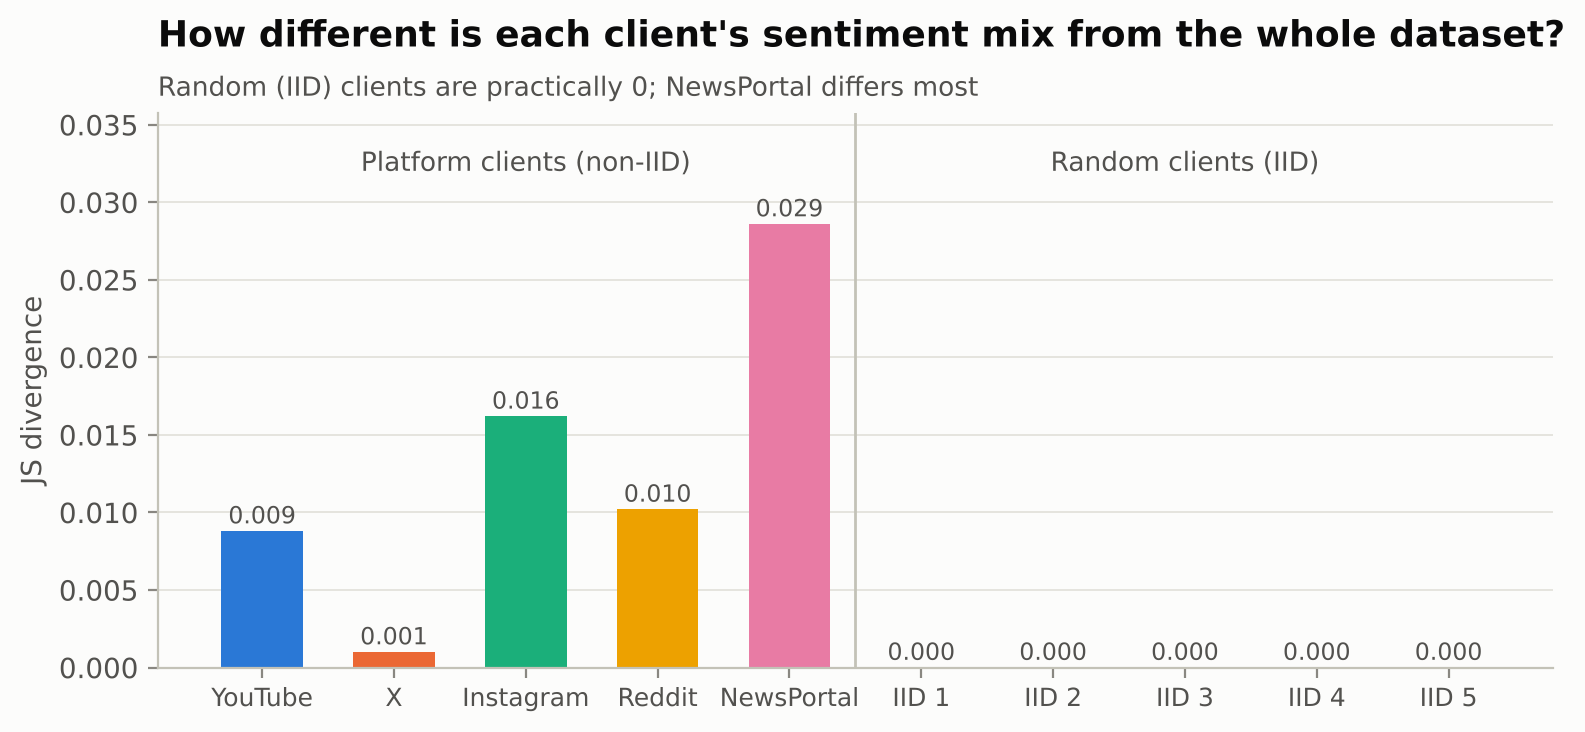

In [6]:
js = stats.set_index("client").js_divergence_from_global
fig, ax = plt.subplots(figsize=(9, 3.6))
names = list(js.index); cols = [PCOL.get(n, MUTED) for n in names]
ax.bar(range(len(js)), js.values, color=cols, width=0.62)
for i, v in enumerate(js.values):
    ax.text(i, v + 0.0005, f"{v:.3f}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(range(len(js)), [n.replace("IID client ", "IID ") for n in names], fontsize=9)
ax.grid(axis="x", visible=False); ax.set_ylabel("JS divergence")
ax.axvline(4.5, color=AXIS, lw=1)
ax.text(2, js.max() * 1.12, "Platform clients (non-IID)", ha="center", fontsize=9.5, color=INK2)
ax.text(7, js.max() * 1.12, "Random clients (IID)", ha="center", fontsize=9.5, color=INK2)
ax.set_ylim(0, js.max() * 1.25)
title(ax, "How different is each client's sentiment mix from the whole dataset?", "Random (IID) clients are practically 0; NewsPortal differs most")
fig.savefig(FIG / "E3_non_iid_vs_iid.png"); plt.show()

## 4. Files created
```
data/clients/          ← main experiment (non-IID, one client per platform)
    youtube_train.csv   youtube_val.csv
    x_train.csv         x_val.csv
    instagram_train.csv instagram_val.csv
    reddit_train.csv    reddit_val.csv
    newsportal_train.csv newsportal_val.csv
data/clients_iid/      ← comparison experiment (5 equal random clients)
    client1_train.csv … client5_train.csv  (+ _val.csv)
```
Every client file contains **only that client's comments**. In Step 7, each client trains on its own file, and the server only ever receives model weights.

**Next:** Step 7 – Federated training with FedAvg.